In [5]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\Admin\AppData\Local\Programs\Python\Python313\python.exe
Python version: 3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]


In [6]:
%pip install tensorflow

  Using cached tensorflow-2.21.0-cp313-cp313-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.1-cp313-cp313-win_amd64.whl.metadata (7.7 kB)
  Using cached grpcio-1.84.0-cp313-cp313-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached h5py-3.14.0-cp313-cp313-win_amd64.whl.metadata (2.7 kB)
  Using cached ml_dtypes-0.6.0-cp313-cp313-win_amd64.whl.metadata (8.8 kB)
  Using cached whe

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("TensorFlo:", tf.__version__)
print("All imports successful!")

TensorFlow: 2.21.0
All imports successful!


In [8]:
np.random.seed(42)

n = 300

area = np.random.randint(500, 3001, n)
bedrooms = np.random.randint(1, 6, n)
age = np.random.randint(0, 41, n)

price = (
    0.035 * area
    + 4 * bedrooms
    - 0.30 * age
    + np.random.normal(0, 3, n)
)

price = np.maximum(price, 5)

df = pd.DataFrame({
    "Area_sqft": area,
    "Bedrooms": bedrooms,
    "Age_years": age,
    "Price_lakh": price
})

df.head()

,Area_sqft,Bedrooms,Age_years,Price_lakh
0,1360,5,17,62.284978
1,1794,5,40,67.718544
2,1630,1,13,61.015219
3,1595,3,14,65.018550
4,2138,2,30,72.150774


In [9]:
print("Dataset shape:", df.shape)

display(df.head(10))
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (300, 4)


,Area_sqft,Bedrooms,Age_years,Price_lakh
0,1360,5,17,62.284978
1,1794,5,40,67.718544
2,1630,1,13,61.015219
3,1595,3,14,65.018550
4,2138,2,30,72.150774
5,2669,1,0,101.930075
6,966,2,2,39.684782
7,1738,2,15,60.604478
8,830,3,22,35.000535
9,1982,2,10,75.429473


,Area_sqft,Bedrooms,Age_years,Price_lakh
count,300.000000,300.000000,300.000000,300.000000
mean,1790.583333,3.080000,19.053333,69.580683
std,687.159533,1.458546,11.906147,25.401311
min,501.000000,1.000000,0.000000,10.552038
25%,1198.750000,2.000000,9.000000,49.472043
50%,1803.000000,3.000000,19.000000,69.990446
75%,2355.500000,4.000000,29.000000,88.609474
max,2989.000000,5.000000,40.000000,126.532473



Missing values:
Area_sqft     0
Bedrooms      0
Age_years     0
Price_lakh    0
dtype: int64


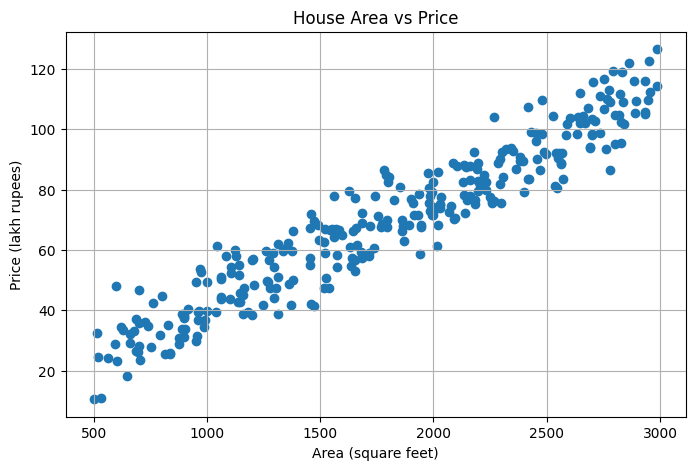

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Area_sqft"], df["Price_lakh"])

plt.xlabel("Area (square feet)")
plt.ylabel("Price (lakh rupees)")
plt.title("House Area vs Price")
plt.grid(True)

plt.show()

In [11]:
X = df[["Area_sqft", "Bedrooms", "Age_years"]]
y = df["Price_lakh"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 240
Testing samples: 60


In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed!")
print(X_train_scaled[:5])

Scaling completed!
[[-0.26073827 -1.3744033   1.46167555]
 [ 0.36727967  0.00575064  1.20704057]
 [-1.27738848 -0.68432633 -1.42418763]
 [-1.66749845 -1.3744033  -0.49052601]
 [-0.70404505  0.69582761 -0.91491765]]


In [13]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3,)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,369 (9.25 KB)

 Trainable params: 2,369 (9.25 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mean_squared_error",
    metrics=["mae"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [15]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=16,
    verbose=1
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - loss: 5845.0347 - mae: 72.2610 - val_loss: 4651.8320 - val_mae: 63.5119
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 5786.7656 - mae: 71.8462 - val_loss: 4597.3730 - val_mae: 63.0488
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 5716.9009 - mae: 71.3479 - val_loss: 4531.5571 - val_mae: 62.4919
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 5632.1973 - mae: 70.7426 - val_loss: 4450.4316 - val_mae: 61.8069
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 5525.1294 - mae: 69.9738 - val_loss: 4347.1772 - val_mae: 60.9317
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 5386.1499 - mae: 68.9748 - val_loss: 4213.1108 - val_mae: 59.8012
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 5205.9858 - mae: 67.6774 - val_loss: 4043.6794 - val_mae: 58.3688
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 4977.6060 - mae: 66.0200 - val_loss: 3833.6921 - val_mae: 

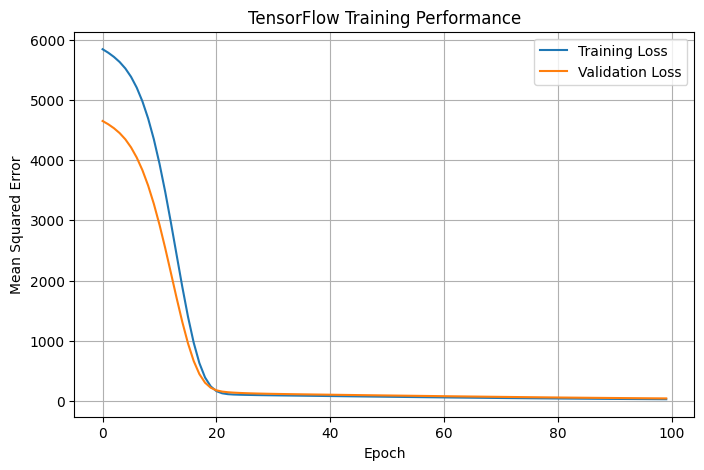

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("TensorFlow Training Performance")
plt.legend()
plt.grid(True)

plt.show()

In [17]:
y_pred = model.predict(
    X_test_scaled,
    verbose=0
).flatten()

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: ₹{mae:.2f} lakh")
print(f"RMSE: ₹{rmse:.2f} lakh")
print(f"R² Score: {r2:.4f}")

MAE: ₹4.22 lakh
RMSE: ₹5.15 lakh
R² Score: 0.9612


In [18]:
new_house = pd.DataFrame({
    "Area_sqft": [1500],
    "Bedrooms": [3],
    "Age_years": [5]
})

new_house_scaled = scaler.transform(new_house)

prediction = model.predict(
    new_house_scaled,
    verbose=0
)[0, 0]

print("House area: 1500 sq ft")
print("Bedrooms: 3")
print("House age: 5 years")
print(f"Predicted price: ₹{prediction:.2f} lakh")

House area: 1500 sq ft
Bedrooms: 3
House age: 5 years
Predicted price: ₹59.21 lakh


In [19]:
model.save("house_price_model.keras")

joblib.dump(
    scaler,
    "house_price_scaler.pkl"
)

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [20]:
loaded_model = tf.keras.models.load_model(
    "house_price_model.keras"
)

loaded_scaler = joblib.load(
    "house_price_scaler.pkl"
)

print("Model loaded:", loaded_model is not None)
print("Scaler loaded:", loaded_scaler is not None)

Model loaded: True
Scaler loaded: True
